# What Sells Together? Market Basket Analysis of 25,728 E-Commerce Orders

**Author:** Pham Hong Hieu (Haven) · **Data:** 51,290 order lines from a beauty and home-care e-commerce retailer,
2020–2023 (synthetic, educational)

## The question

The merchandising team wants to build bundles and "frequently bought together" recommendations. Before designing
them, they need evidence on three points:

1. Which product subcategories are bought in the same order?
2. Are those combinations **stronger than chance**, or just the result of both items being popular?
3. Which recommendations does the evidence support, and which ones are noise?

Two methods are used and compared: a transparent **self-join** that counts co-purchases, and the **Apriori**
algorithm, which computes support, confidence and lift for every itemset.

## 1. Setup and data loading

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore", category=DeprecationWarning)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "figure.dpi": 110})

DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
TABLE_DIR = Path("../reports/tables")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
sales = pd.read_csv(DATA_DIR / "EcomSales.csv")
products = pd.read_csv(DATA_DIR / "Product.csv")
print(f"Order lines: {len(sales):,} | Orders: {sales['OrderID'].nunique():,} | Products: {len(products):,}")
print("Missing values:", int(sales.isna().sum().sum() + products.isna().sum().sum()),
      "| Duplicate lines:", int(sales.duplicated().sum()))

Order lines: 51,290 | Orders: 25,728 | Products: 28,356
Missing values: 0 | Duplicate lines: 0


## 2. Data preparation

Two product codes in the sales table have a tripled prefix (`PPP000002`) and would be lost in the join, so they are
corrected first. The analysis works at **subcategory** level (17 subcategories). Individual products are too
numerous (more than 3,500) and too rarely repeated for association rules to be reliable.

In [3]:
print("Unmatched product codes before fix:", (~sales["ProductCode"].isin(products["ProductCode"])).sum())
sales["ProductCode"] = sales["ProductCode"].replace({"PPP000002": "P000002", "PPP000010": "P000010"})
lines = sales[["OrderID", "ProductCode"]].merge(products[["ProductCode", "Category", "Subcategory"]],
                                                on="ProductCode", how="inner", validate="many_to_one")
assert len(lines) == len(sales), "Some order lines did not match a product."

baskets = lines.groupby("OrderID")["Subcategory"].apply(lambda s: sorted(set(s)))
basket_size = baskets.str.len()
print(f"Orders: {len(baskets):,} | Subcategories: {lines['Subcategory'].nunique()}")
print(f"Orders containing a single subcategory: {(basket_size == 1).mean():.1%}")

Unmatched product codes before fix: 2


Orders: 25,728 | Subcategories: 17
Orders containing a single subcategory: 52.1%


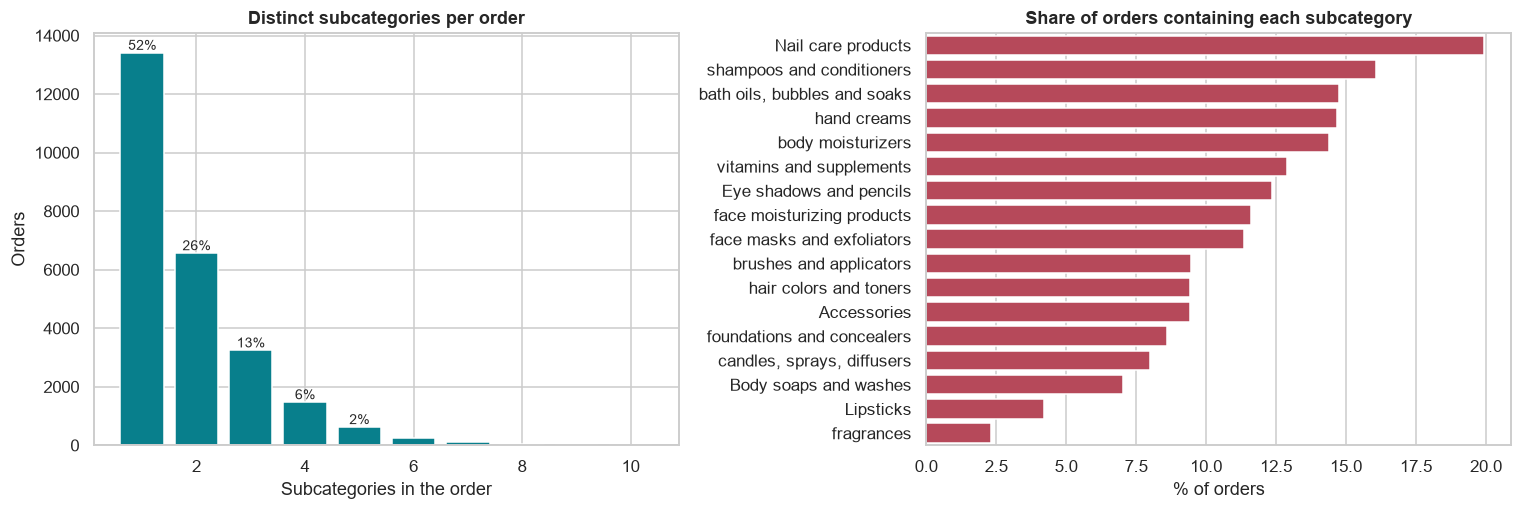

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
size_counts = basket_size.value_counts().sort_index()
axes[0].bar(size_counts.index, size_counts.values, color="#087F8C")
axes[0].set(title="Distinct subcategories per order", xlabel="Subcategories in the order", ylabel="Orders")
for x, y in zip(size_counts.index[:5], size_counts.values[:5]):
    axes[0].text(x, y, f"{y / len(baskets):.0%}", ha="center", va="bottom", fontsize=9)

penetration = (lines.drop_duplicates(["OrderID", "Subcategory"])["Subcategory"].value_counts() / len(baskets) * 100)
sns.barplot(x=penetration.values, y=penetration.index, color="#C8374D", ax=axes[1])
axes[1].set(title="Share of orders containing each subcategory", xlabel="% of orders", ylabel="")
fig.tight_layout()
save(fig, "01_basket_size_and_penetration")
plt.show()

Half of all orders contain only one subcategory. Nail care is the most common item, in one order out of five. Any
co-purchase count has to be read against these base rates. Popular items will appear together often even if
customers do not deliberately buy them as a pair.

## 3. Method 1: self-join co-occurrence

Joining the order table to itself on `OrderID` lists every pair of subcategories bought in the same order. Keeping
only pairs where item A sorts before item B removes self-pairs and mirrored duplicates.

In [5]:
unique_lines = lines[["OrderID", "Subcategory"]].drop_duplicates()
pairs = unique_lines.merge(unique_lines, on="OrderID")
pairs = pairs[pairs["Subcategory_x"] < pairs["Subcategory_y"]]
pair_counts = (pairs.groupby(["Subcategory_x", "Subcategory_y"]).size()
               .reset_index(name="orders").sort_values("orders", ascending=False, ignore_index=True))

orders_with = unique_lines["Subcategory"].value_counts()
n_orders = len(baskets)
pair_counts["support"] = pair_counts["orders"] / n_orders
pair_counts["confidence_x_to_y"] = pair_counts["orders"] / pair_counts["Subcategory_x"].map(orders_with)
pair_counts["confidence_y_to_x"] = pair_counts["orders"] / pair_counts["Subcategory_y"].map(orders_with)
pair_counts["lift"] = pair_counts["support"] / (
    pair_counts["Subcategory_x"].map(orders_with) / n_orders * pair_counts["Subcategory_y"].map(orders_with) / n_orders)
pair_counts.to_csv(TABLE_DIR / "subcategory_pairs.csv", index=False)
pair_counts.head(10)

,Subcategory_x,Subcategory_y,orders,support,confidence_x_to_y,confidence_y_to_x,lift
0,Nail care products,"bath oils, bubbles and soaks",716,0.027830,0.139762,0.188520,0.946760
1,Nail care products,hand creams,702,0.027285,0.137029,0.185714,0.932668
2,Nail care products,body moisturizers,693,0.026936,0.135272,0.187297,0.940618
3,Nail care products,shampoos and conditioners,685,0.026625,0.133711,0.165539,0.831346
4,Nail care products,vitamins and supplements,641,0.024914,0.125122,0.193305,0.970790
5,Eye shadows and pencils,Nail care products,574,0.022310,0.180787,0.112044,0.907925
6,"bath oils, bubbles and soaks",shampoos and conditioners,572,0.022233,0.150606,0.138231,0.936390
7,body moisturizers,shampoos and conditioners,543,0.021105,0.146757,0.131223,0.912460
8,Nail care products,face moisturizing products,539,0.020950,0.105212,0.180812,0.908047
9,"bath oils, bubbles and soaks",hand creams,528,0.020522,0.139021,0.139683,0.946222


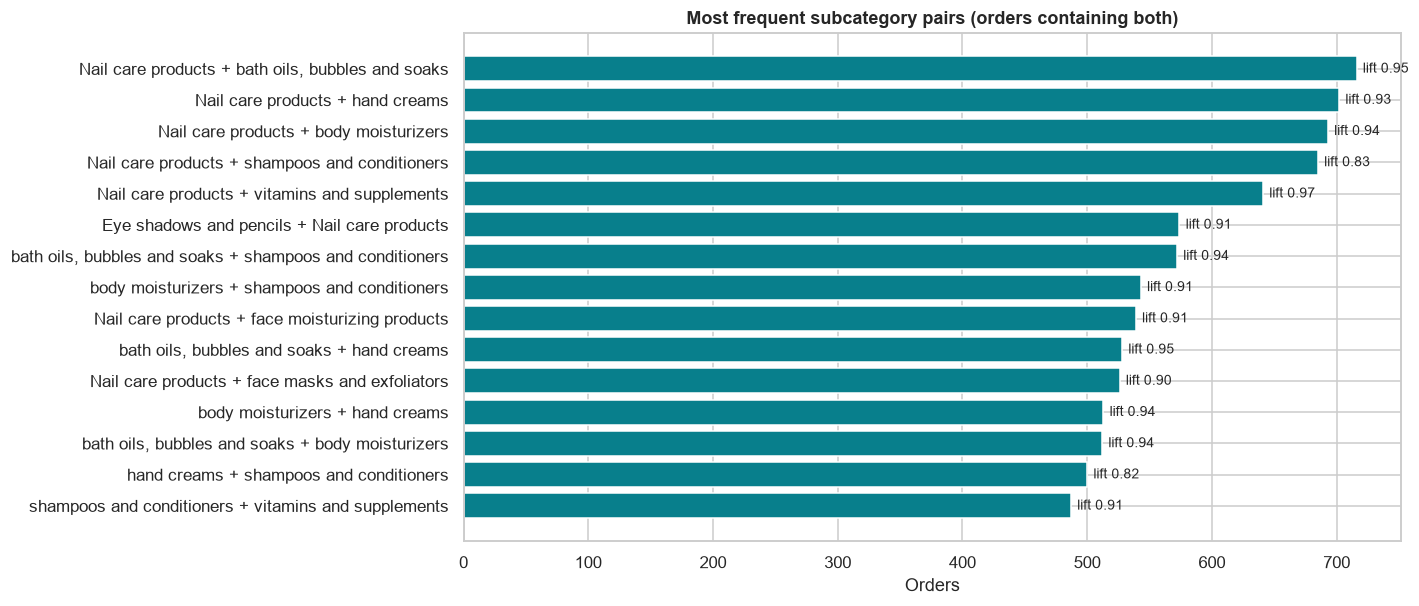

In [6]:
top_pairs = pair_counts.head(15).copy()
top_pairs["pair"] = top_pairs["Subcategory_x"] + " + " + top_pairs["Subcategory_y"]
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top_pairs["pair"][::-1], top_pairs["orders"][::-1], color="#087F8C")
for bar, lift in zip(bars, top_pairs["lift"][::-1]):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height() / 2, f"lift {lift:.2f}", va="center", fontsize=9)
ax.set(title="Most frequent subcategory pairs (orders containing both)", xlabel="Orders", ylabel="")
save(fig, "02_top_pairs")
plt.show()

The most frequent pairs all involve nail care, hand creams, bath products and body moisturisers, the four most popular
subcategories. Their lift is slightly **below** 1 (0.83 to 0.97), so they appear together a little less often than
their popularity alone would predict. **High frequency is not evidence of a real association.**

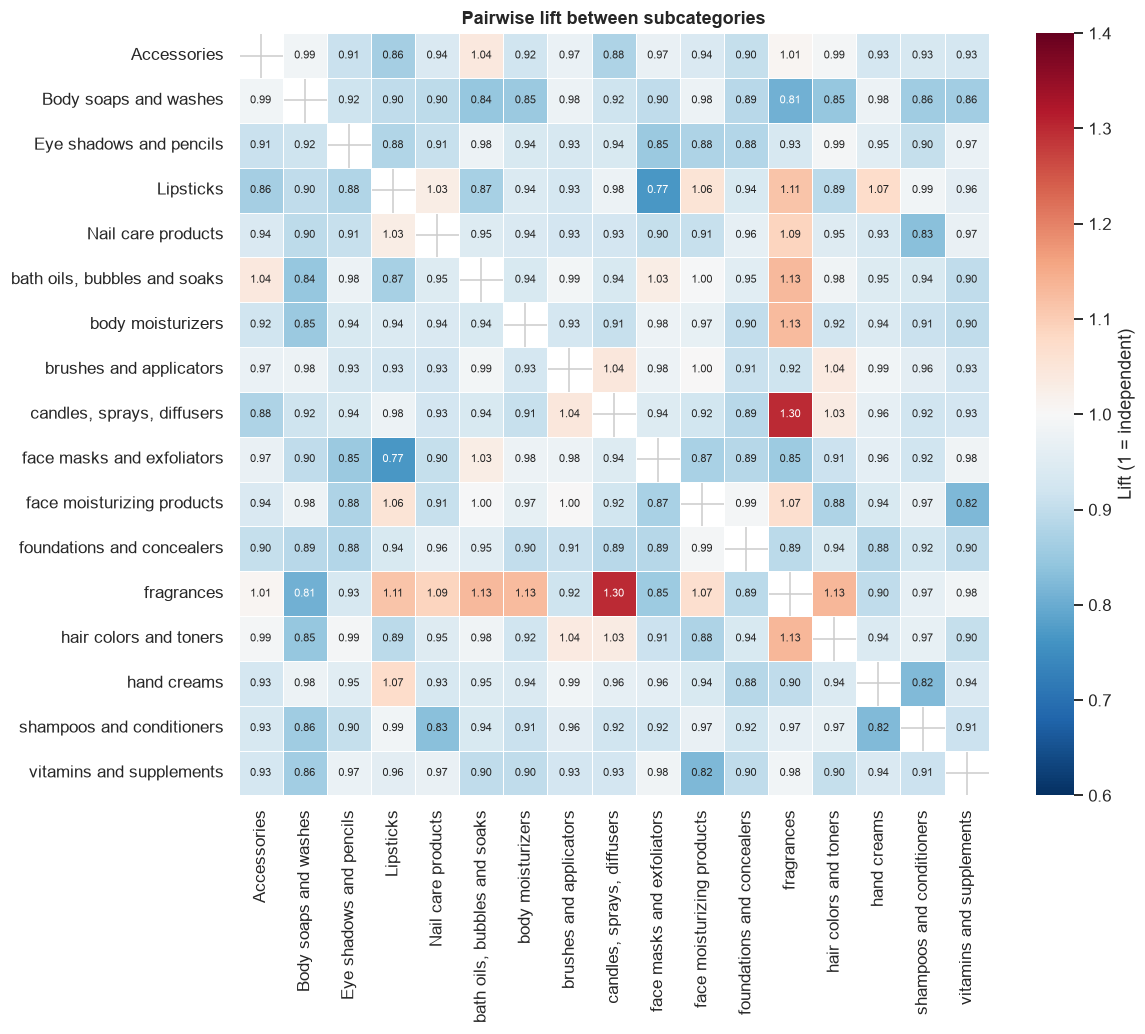

Pairwise lift ranges from 0.77 to 1.30


In [7]:
items = sorted(orders_with.index)
lift_matrix = pd.DataFrame(np.nan, index=items, columns=items)
for row in pair_counts.itertuples():
    lift_matrix.loc[row.Subcategory_x, row.Subcategory_y] = row.lift
    lift_matrix.loc[row.Subcategory_y, row.Subcategory_x] = row.lift

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(lift_matrix, cmap="RdBu_r", center=1, vmin=0.6, vmax=1.4, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"label": "Lift (1 = independent)"}, ax=ax)
ax.set_title("Pairwise lift between subcategories")
save(fig, "03_lift_heatmap")
plt.show()
print(f"Pairwise lift ranges from {pair_counts['lift'].min():.2f} to {pair_counts['lift'].max():.2f}")

## 4. Method 2: Apriori association rules

Apriori finds every itemset above a minimum support and derives rules A → B with:

- **Support:** share of all orders containing both A and B.
- **Confidence:** share of orders with A that also contain B.
- **Lift:** confidence divided by B's overall frequency. A lift of 1 means no association.

In [8]:
encoder = TransactionEncoder()
basket_matrix = pd.DataFrame(encoder.fit(baskets).transform(baskets), columns=encoder.columns_)

itemsets_low = apriori(basket_matrix, min_support=0.001, use_colnames=True)
rules_low = association_rules(itemsets_low, metric="confidence", min_threshold=0.1)
rules_low["orders"] = (rules_low["support"] * n_orders).round().astype(int)
print(f"min_support 0.1%: {len(itemsets_low):,} itemsets, {len(rules_low):,} rules")


def readable(rules):
    out = rules.copy()
    out["rule"] = (out["antecedents"].apply(lambda s: " + ".join(sorted(s))) + "  ->  "
                   + out["consequents"].apply(lambda s: " + ".join(sorted(s))))
    return out[["rule", "orders", "support", "confidence", "lift"]]


readable(rules_low.sort_values("lift", ascending=False)).head(10)

min_support 0.1%: 612 itemsets, 1,435 rules


,rule,orders,support,confidence,lift
1366,"candles, sprays, diffusers + face masks and ex...",26,0.001011,0.118182,4.246623
1364,"Nail care products + bath oils, bubbles and so...",26,0.001011,0.346667,3.054466
1363,"Nail care products + candles, sprays, diffuser...",26,0.001011,0.419355,2.840748
1429,face masks and exfoliators + hand creams + sha...,27,0.001049,0.391304,2.650732
1365,"Nail care products + bath oils, bubbles and so...",26,0.001011,0.208000,2.606636
1433,hand creams + shampoos and conditioners + vita...,26,0.001011,0.292135,2.521317
1407,Nail care products + brushes and applicators +...,27,0.001049,0.369863,2.517417
1410,Nail care products + hand creams + vitamins an...,27,0.001049,0.232759,2.459308
1409,Nail care products + brushes and applicators +...,27,0.001049,0.303371,2.353777
1430,"bath oils, bubbles and soaks + hand creams + s...",27,0.001049,0.264706,2.332313


### The small-support trap

At a 0.1% support threshold, the strongest rules reach a lift of about 4. But each rule rests on only about **26
orders** out of 25,728. With 17 subcategories there are thousands of possible itemsets, and with that many
candidates some small combinations will show high lift by chance alone. Rules this thin should not drive merchandising
decisions.

The test is to raise the threshold so that every rule is backed by at least about 130 orders (0.5% support).

In [9]:
itemsets = apriori(basket_matrix, min_support=0.005, use_colnames=True)
rules = association_rules(itemsets, metric="lift", min_threshold=1.0)
rules["orders"] = (rules["support"] * n_orders).round().astype(int)
robust = readable(rules.sort_values("lift", ascending=False))
robust.to_csv(TABLE_DIR / "robust_rules.csv", index=False)
print(f"min_support 0.5%: {len(itemsets):,} itemsets, {len(rules):,} rules with lift > 1")
print(f"Highest lift among robust rules: {rules['lift'].max():.2f}")
robust.head(10)

min_support 0.5%: 134 itemsets, 44 rules with lift > 1
Highest lift among robust rules: 1.38


,rule,orders,support,confidence,lift
20,"bath oils, bubbles and soaks + body moisturize...",141,0.005480,0.275391,1.383028
25,"Nail care products -> bath oils, bubbles and...",141,0.005480,0.027523,1.383028
24,"bath oils, bubbles and soaks -> Nail care pr...",141,0.005480,0.037125,1.378278
21,Nail care products + body moisturizers -> ba...,141,0.005480,0.203463,1.378278
23,body moisturizers -> Nail care products + ba...,141,0.005480,0.038108,1.369337
22,"Nail care products + bath oils, bubbles and so...",141,0.005480,0.196927,1.369337
42,Nail care products -> hand creams + shampoos...,132,0.005131,0.025766,1.325823
39,hand creams + shampoos and conditioners -> N...,132,0.005131,0.264000,1.325823
38,Nail care products + shampoos and conditioners...,132,0.005131,0.192701,1.311588
43,hand creams -> Nail care products + shampoos...,132,0.005131,0.034921,1.311588


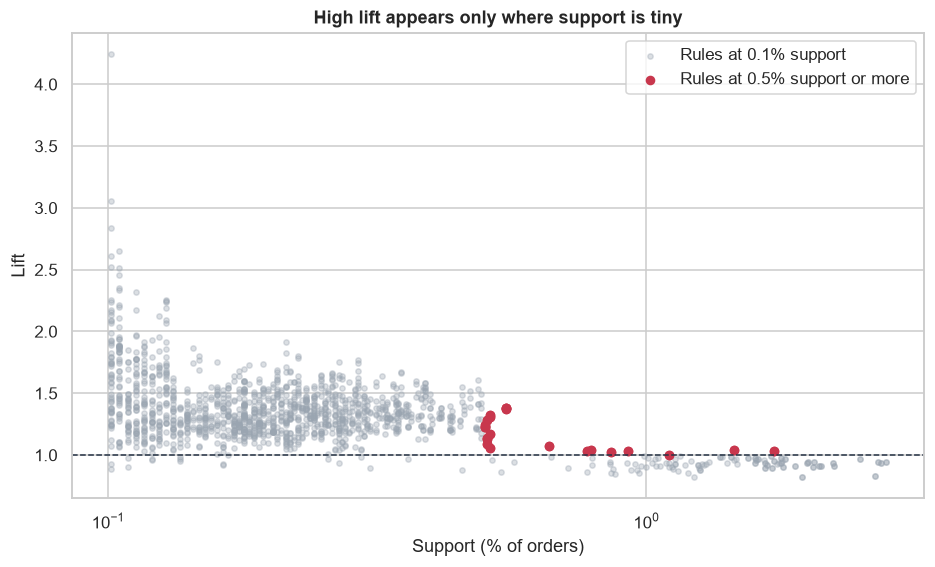

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(rules_low["support"] * 100, rules_low["lift"], s=12, alpha=0.35, color="#9AA5B1", label="Rules at 0.1% support")
ax.scatter(rules["support"] * 100, rules["lift"], s=28, color="#C8374D", label="Rules at 0.5% support or more")
ax.axhline(1, color="#263345", linestyle="--", linewidth=1)
ax.set(title="High lift appears only where support is tiny", xlabel="Support (% of orders)", ylabel="Lift",
       xscale="log")
ax.legend()
save(fig, "04_support_vs_lift")
plt.show()

The chart shows the pattern. Every rule with a lift above about 1.7 sits at the far left, where support is lowest,
and lift falls toward 1 as support grows.
Once each rule needs at least about 130 orders, the strongest association is a **lift of about 1.4**: bath products +
body moisturisers → nail care. That is a modest effect. Customers do lean toward combining body-care items, but no
pairing is strong enough to justify a dedicated bundle on its own.

## 5. Findings and recommendations

In [11]:
summary = {
    "Orders analysed": f"{n_orders:,}",
    "Single-subcategory orders": f"{(basket_size == 1).mean():.1%}",
    "Most common subcategory": f"{penetration.index[0]} ({penetration.iloc[0]:.1f}% of orders)",
    "Pairwise lift range": f"{pair_counts['lift'].min():.2f} - {pair_counts['lift'].max():.2f}",
    "Max lift, rules with >= 0.5% support": f"{rules['lift'].max():.2f}",
    "Max lift, rules with >= 0.1% support": f"{rules_low['lift'].max():.2f} (about {rules_low.loc[rules_low['lift'].idxmax(), 'orders']} orders)",
}
pd.Series(summary, name="value").to_frame()

,value
Orders analysed,"25,728"
Single-subcategory orders,52.1%
Most common subcategory,Nail care products (19.9% of orders)
Pairwise lift range,0.77 - 1.30
"Max lift, rules with >= 0.5% support",1.38
"Max lift, rules with >= 0.1% support",4.25 (about 26 orders)


**What the evidence supports**

1. **Grow basket size, not specific pairs.** Half of all orders contain a single subcategory. Generic
   cross-sell prompts ("complete your routine"), free-shipping thresholds and multi-buy offers address the larger
   opportunity.
2. **Use popular items for reach, and the mild affinities for targeting.** Nail care, hand creams, bath products and
   body moisturisers reach the most baskets, which makes them good default "you may also like" items, even though
   their pairwise lift is below 1. The only consistent affinities are three-item body-care combinations (lift 1.3
   to 1.4, about 130–140 orders each) and candles + fragrances (lift 1.30, 62 orders).
3. **Test before bundling.** A bundle such as bath products + body moisturisers + nail care deserves an A/B test,
   not a permanent catalogue change. Measure its uplift in average order value against a control.

**What the evidence does not support**

- Bundles built on rules with lift above 2. These rely on fewer than 30 orders each and are very likely chance
  patterns.

## 6. Limitations

- The data are synthetic and educational. Their weak associations may reflect how they were generated rather than
  real shopper behaviour.
- The analysis works at subcategory level. Product-level associations might exist but would need far more orders
  per product to measure.
- Association does not prove causation. Only a controlled test shows whether a recommendation changes what people buy.